In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv('Algerian_forest_fires_cleaned_dataset.csv')

In [3]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
1,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
2,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
3,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0
4,6,6,2012,31,67,14,0,82.6,5.8,22.2,3.1,7,2.5,fire,0


In [4]:
df.columns

Index(['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Region'],
      dtype='object')

In [5]:
##drop month,day and yyear
df.drop(['day','month','year'],axis=1,inplace=True)

In [6]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0
1,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
2,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0
3,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0
4,31,67,14,0,82.6,5.8,22.2,3.1,7,2.5,fire,0


In [7]:
df['Classes'].value_counts()

Classes
fire             131
not fire          99
fire               4
fire               2
not fire           2
not fire           1
Classes            1
not fire           1
not fire           1
Name: count, dtype: int64

In [8]:
## Encoding
df['Classes']=np.where(df['Classes'].str.contains("not fire"),0,1)

In [9]:
df.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
237,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,1,1
238,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,0,1
239,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
240,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1
241,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,0,1


In [10]:
df['Classes'].value_counts()

Classes
1    138
0    104
Name: count, dtype: int64

In [11]:
## Independent And dependent features
X=df.drop('FWI',axis=1)
y=df['FWI']

In [12]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0,0
1,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
2,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,0
3,27,77,16,0,64.8,3,14.2,1.2,3.9,0,0
4,31,67,14,0,82.6,5.8,22.2,3.1,7,1,0


In [13]:
y

0      0.4
1      0.1
2        0
3      0.5
4      2.5
      ... 
237    6.5
238      0
239    0.2
240    0.7
241    0.5
Name: FWI, Length: 242, dtype: object

In [14]:
#Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [15]:
X_train.shape,X_test.shape

((181, 11), (61, 11))

In [16]:
## Feature Selection based on correlaltion
## Feature Selection based on correlation

# Convert object columns to numeric values
X_train = X_train.apply(pd.to_numeric, errors='coerce')
X_test = X_test.apply(pd.to_numeric, errors='coerce')
y_train = pd.to_numeric(y_train, errors='coerce')
y_test = pd.to_numeric(y_test, errors='coerce')

# Remove rows containing invalid values, such as repeated CSV headers
train_valid = X_train.notna().all(axis=1) & y_train.notna()
test_valid = X_test.notna().all(axis=1) & y_test.notna()

X_train = X_train.loc[train_valid]
y_train = y_train.loc[train_valid]

X_test = X_test.loc[test_valid]
y_test = y_test.loc[test_valid]

# Display the correlation matrix
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.647741,-0.276127,-0.345625,0.708552,0.494037,0.376796,0.630239,0.466328,0.546780,0.254625
RH,-0.647741,1.000000,0.236882,0.235231,-0.641681,-0.416286,-0.248317,-0.700062,-0.366139,-0.456196,-0.378673
Ws,-0.276127,0.236882,1.000000,0.182994,-0.131081,-0.006385,0.095144,0.026390,0.031489,-0.037754,-0.244082
Rain,-0.345625,0.235231,0.182994,1.000000,-0.555837,-0.287085,-0.297555,-0.344001,-0.297742,-0.376412,-0.068332
FFMC,0.708552,-0.641681,-0.131081,-0.555837,1.000000,0.613277,0.530854,0.743522,0.603259,0.765375,0.218626
DMC,0.494037,-0.416286,-0.006385,-0.287085,0.613277,1.000000,0.874945,0.690725,0.983180,0.619311,0.194553
DC,0.376796,-0.248317,0.095144,-0.297555,0.530854,0.874945,1.000000,0.550815,0.946811,0.553737,-0.087395
ISI,0.630239,-0.700062,0.026390,-0.344001,0.743522,0.690725,0.550815,1.000000,0.658246,0.756260,0.260062
BUI,0.466328,-0.366139,0.031489,-0.297742,0.603259,0.983180,0.946811,0.658246,1.000000,0.616592,0.092050
Classes,0.546780,-0.456196,-0.037754,-0.376412,0.765375,0.619311,0.553737,0.756260,0.616592,1.000000,0.167791


<Axes: >

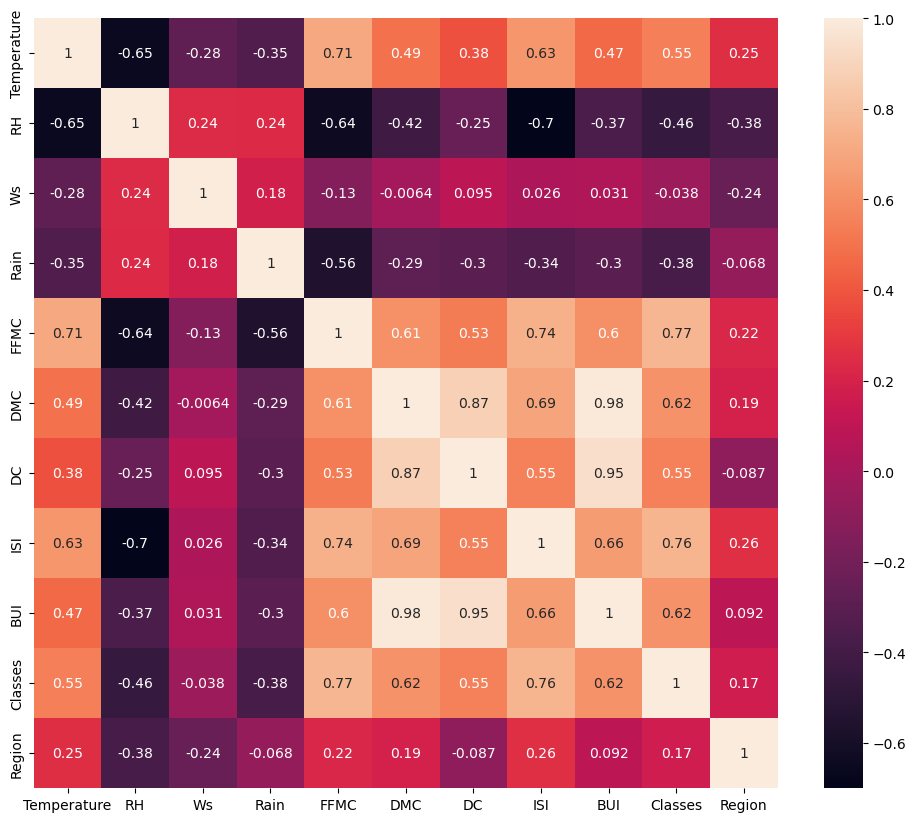

In [17]:
## Check for multicollinearity
plt.figure(figsize=(12,10))
corr=X_train.corr()
sns.heatmap(corr,annot=True)


In [18]:
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.647741,-0.276127,-0.345625,0.708552,0.494037,0.376796,0.630239,0.466328,0.546780,0.254625
RH,-0.647741,1.000000,0.236882,0.235231,-0.641681,-0.416286,-0.248317,-0.700062,-0.366139,-0.456196,-0.378673
Ws,-0.276127,0.236882,1.000000,0.182994,-0.131081,-0.006385,0.095144,0.026390,0.031489,-0.037754,-0.244082
Rain,-0.345625,0.235231,0.182994,1.000000,-0.555837,-0.287085,-0.297555,-0.344001,-0.297742,-0.376412,-0.068332
FFMC,0.708552,-0.641681,-0.131081,-0.555837,1.000000,0.613277,0.530854,0.743522,0.603259,0.765375,0.218626
DMC,0.494037,-0.416286,-0.006385,-0.287085,0.613277,1.000000,0.874945,0.690725,0.983180,0.619311,0.194553
DC,0.376796,-0.248317,0.095144,-0.297555,0.530854,0.874945,1.000000,0.550815,0.946811,0.553737,-0.087395
ISI,0.630239,-0.700062,0.026390,-0.344001,0.743522,0.690725,0.550815,1.000000,0.658246,0.756260,0.260062
BUI,0.466328,-0.366139,0.031489,-0.297742,0.603259,0.983180,0.946811,0.658246,1.000000,0.616592,0.092050
Classes,0.546780,-0.456196,-0.037754,-0.376412,0.765375,0.619311,0.553737,0.756260,0.616592,1.000000,0.167791


In [19]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: 
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [20]:
## threshold--Domain expertise
corr_features=correlation(X_train,0.85)

In [21]:
corr_features

{'BUI', 'DC'}

In [22]:
## drop features when correlation is more than 0.85 
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.shape,X_test.shape

((180, 9), (61, 9))

## Feature Scaling Or Standardization

In [23]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [24]:
X_train_scaled

array([[-0.28983683,  0.5338332 ,  0.56302325, ..., -0.7559909 ,
        -1.06904497, -0.98894994],
       [-0.02366015, -0.53531813, -0.5345672 , ...,  0.07361068,
         0.93541435,  1.01117353],
       [-0.82219019, -1.47082555, -2.7297481 , ..., -0.47155607,
         0.93541435,  1.01117353],
       ...,
       [-2.68542696,  1.53616258, -0.16870372, ..., -1.11153443,
        -1.06904497, -0.98894994],
       [ 1.04104657, -0.46849617,  0.19715977, ...,  0.83210355,
         0.93541435,  1.01117353],
       [-0.82219019,  1.66980649, -0.90043068, ..., -0.8270996 ,
        -1.06904497, -0.98894994]], shape=(180, 9))

## Box Plots To understand Effect Of Standard Scaler

Text(0.5, 1.0, 'X_train After Scaling')

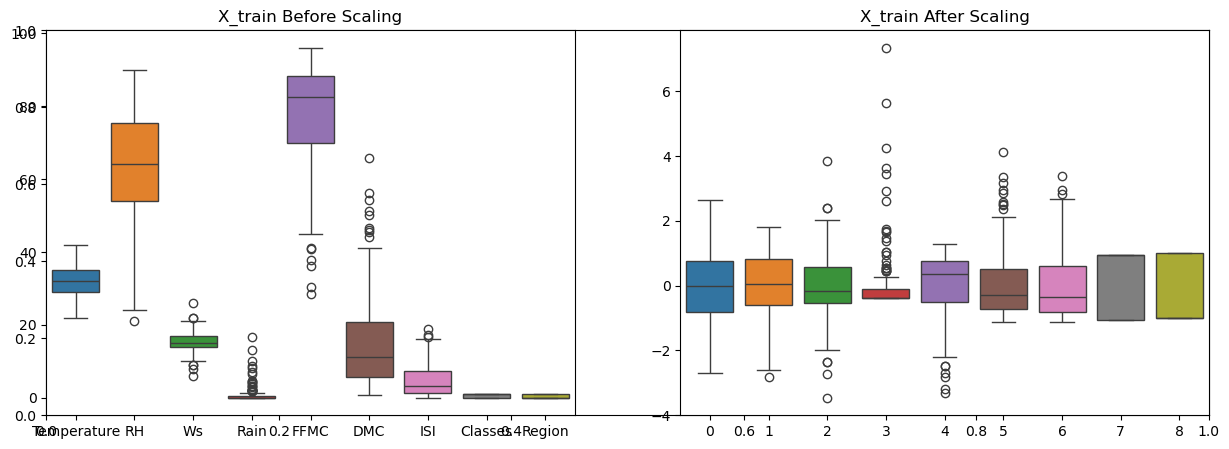

In [25]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

## Linear Regression Model

Mean absolute error 0.6005655512782201
R2 Score 0.9814428009681544


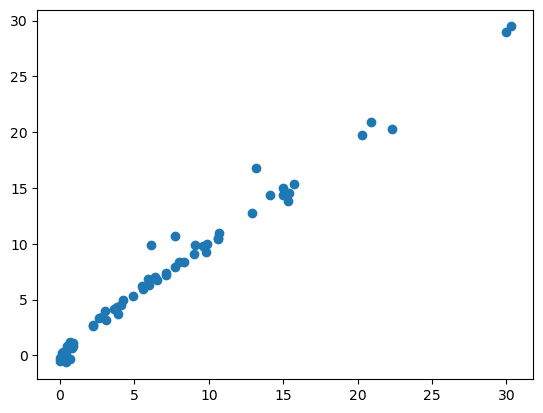

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
linreg=LinearRegression()
linreg.fit(X_train_scaled,y_train)
y_pred=linreg.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

## Lasso Regression

Mean absolute error 1.105548237499327
R2 Score 0.9520695432907427


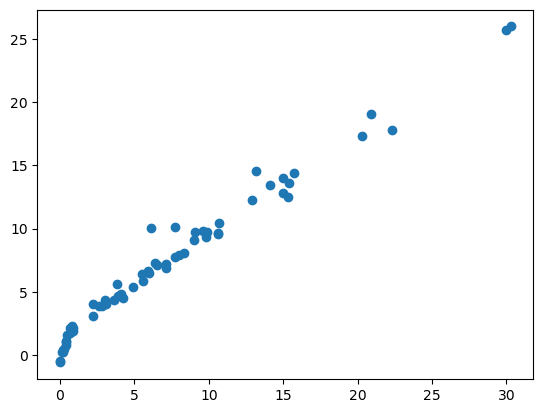

In [27]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred=lasso.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

### Cross Validation Lasso

In [28]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,1000
,tol,0.0001
,copy_X,True
,cv,5
,verbose,False
,n_jobs,None


Mean absolute error 0.6392370547847314
R2 Score 0.980774292260952


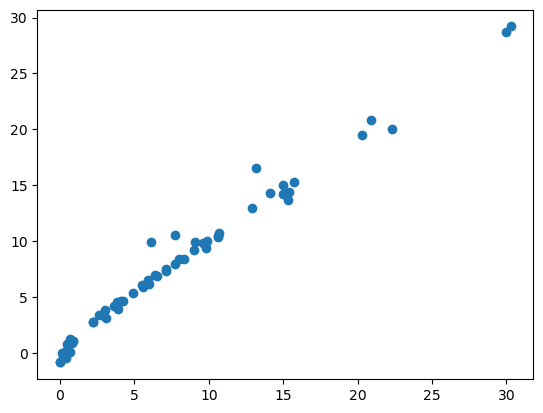

In [29]:
y_pred=lassocv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

## Ridge Regression model

Mean absolute error 0.6318764060639467
R2 Score 0.9804912645959246


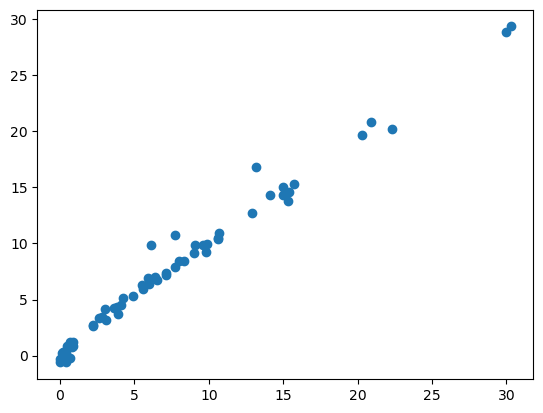

In [30]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred=ridge.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

Mean absolute error 0.8853727370726793
R2 Score 0.9704336819170927


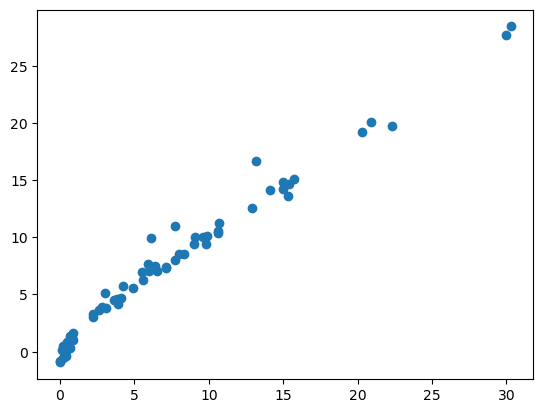

In [31]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)
y_pred=ridgecv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

In [32]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': False}

## Elasticnet Regression

Mean absolute error 1.8975982601422912
R2 Score 0.8719318808512687


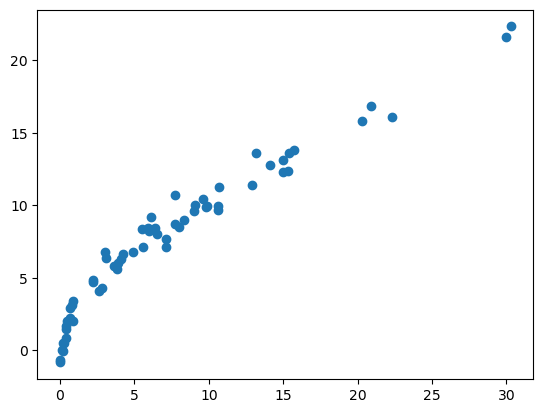

In [33]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
elastic=ElasticNet()
elastic.fit(X_train_scaled,y_train)
y_pred=elastic.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

Mean absolute error 0.7218570264417059
R2 Score 0.9777718563593


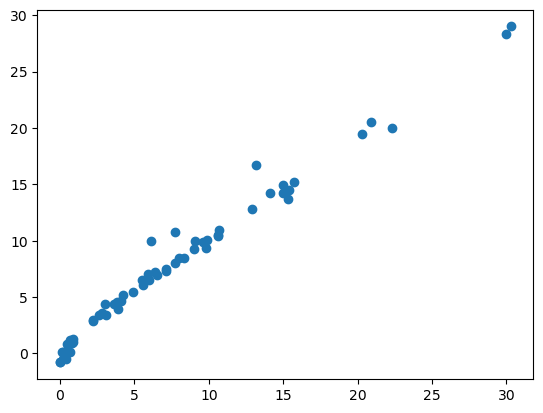

In [34]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)
y_pred=elasticcv.predict(X_test_scaled)
plt.scatter(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)

In [35]:
elasticcv.alphas_

array([13.87973711, 12.94428929, 12.07188751, 11.2582827 , 10.49951212,
        9.79188015,  9.1319402 ,  8.51647799,  7.94249588,  7.40719824,
        6.90797787,  6.44240328,  6.00820686,  5.60327383,  5.22563193,
        4.87344182,  4.54498816,  4.23867116,  3.95299891,  3.68658002,
        3.43811686,  3.20639929,  2.99029871,  2.78876259,  2.60080932,
        2.42552348,  2.26205131,  2.10959663,  1.96741687,  1.83481956,
        1.71115886,  1.59583248,  1.48827872,  1.38797371,  1.29442893,
        1.20718875,  1.12582827,  1.04995121,  0.97918801,  0.91319402,
        0.8516478 ,  0.79424959,  0.74071982,  0.69079779,  0.64424033,
        0.60082069,  0.56032738,  0.52256319,  0.48734418,  0.45449882,
        0.42386712,  0.39529989,  0.368658  ,  0.34381169,  0.32063993,
        0.29902987,  0.27887626,  0.26008093,  0.24255235,  0.22620513,
        0.21095966,  0.19674169,  0.18348196,  0.17111589,  0.15958325,
        0.14882787,  0.13879737,  0.12944289,  0.12071888,  0.11

In [36]:
# Pickle the machine learning models, preprocessing model standardscaler

In [37]:
scaler

,copy,True
,with_mean,True
,with_std,True


In [38]:
ridge

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [39]:
import pickle
pickle.dump(scaler, open('scaler.pkl','wb'))
pickle.dump(ridge, open('ridge.pkl','wb'))